# Exercise 2: Tune a Saturation Prior

The Hill curve $f(x) = x^s / (x^s + k^s)$ turns adstocked media into a diminishing-returns response, with a half-saturation point $k$ and a shape $s$ (`half` and `slope` in `mmm_book.saturation.hill_saturation`).
Like the case-study model, this exercise fixes $s = 1$, so the curve is concave from the first pound (Chapter 14), and writes $k$ as a multiple of the channel's average adstocked spend, so $k = 1$ puts the half-saturation point at a typical week.
The task is to choose a prior for $k$ on a Sedge Meta series, in the book's form LogNormal(median, log-scale standard deviation), and to check it the way Chapter 17 checks every prior: by the curves it implies.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from mmm_book import RANDOM_SEED
from mmm_book.adstock import geometric_adstock
from mmm_book.plotting import mmm_style
from mmm_book.saturation import hill_saturation
from mmm_book.sedge import ADSTOCK_ALPHA, HALF_MULT, HILL_SLOPE, generate_sedge

mmm_style()
rng = np.random.default_rng(RANDOM_SEED)

In [2]:
df = generate_sedge(seed=RANDOM_SEED)
channel = "meta"
spend = df.loc[df["region"] == "region_0", channel + "_spend"].to_numpy(dtype=float)
adstocked = geometric_adstock(spend, alpha=ADSTOCK_ALPHA[channel], normalize=True)
average = adstocked.mean()

levels = np.percentile(adstocked, [10, 50, 90])
print(
    "adstocked Meta spend: "
    + ", ".join(
        f"p{p}={x:,.0f} ({x / average:.2f} x average)"
        for p, x in zip([10, 50, 90], levels, strict=True)
    )
)

adstocked Meta spend: p10=1,175 (0.67 x average), p50=1,667 (0.96 x average), p90=2,342 (1.34 x average)


## Task

Meta is bought in auctions, where the cheapest impressions go first, so the team expects its curve to bend near current spend, but it has no experiment on Meta's curve and wants the data to have room to decide.
Choose `k_median` and `k_sigma`, the two numbers of a LogNormal(median, log-scale standard deviation) prior on $k$, so that the curves the prior implies meet this brief at three spend levels, the 10th, 50th and 90th percentiles of adstocked spend above:

- bends near current spend: at p50, the prior's median response is between 0.3 and 0.7
- room for the data: at p50, the prior's 90 per cent range of response reaches below 0.3 and above 0.7
- no impossible businesses: fewer than 5 per cent of prior curves are already more than 90 per cent saturated at p10, and fewer than 5 per cent are still below 5 per cent saturation at p90

The cell draws 4,000 values of $k$ from your prior and evaluates each curve at the three levels.
Remember the book's convention: the first number is the median itself, which the cell multiplies by $e^{\sigma z}$ for standard Normal draws $z$.
PyMC's `mu` would be its logarithm (Chapter 17).

In [3]:
# YOUR CODE HERE: choose the prior's median and log-scale standard deviation.
# Deliberately poor default: a confident prior that every curve is saturated almost at once.
k_median = 0.05
k_sigma = 0.1
k_draws = k_median * np.exp(k_sigma * rng.standard_normal(4000))
response = np.stack([hill_saturation(levels, half=k * average, slope=1.0) for k in k_draws])

lo, med, hi = np.percentile(response, [5, 50, 95], axis=0)
for i, p in enumerate([10, 50, 90]):
    print(f"p{p}: prior median response {med[i]:.2f}, 90% range {lo[i]:.2f} to {hi[i]:.2f}")

p10: prior median response 0.93, 90% range 0.92 to 0.94
p50: prior median response 0.95, 90% range 0.94 to 0.96
p90: prior median response 0.96, 90% range 0.96 to 0.97


## A look at the curves

The plot draws 100 curves from your prior, with the 90 per cent band, against the adstocked spend Meta actually ran, so you can see the shape you have picked before running the self-check.

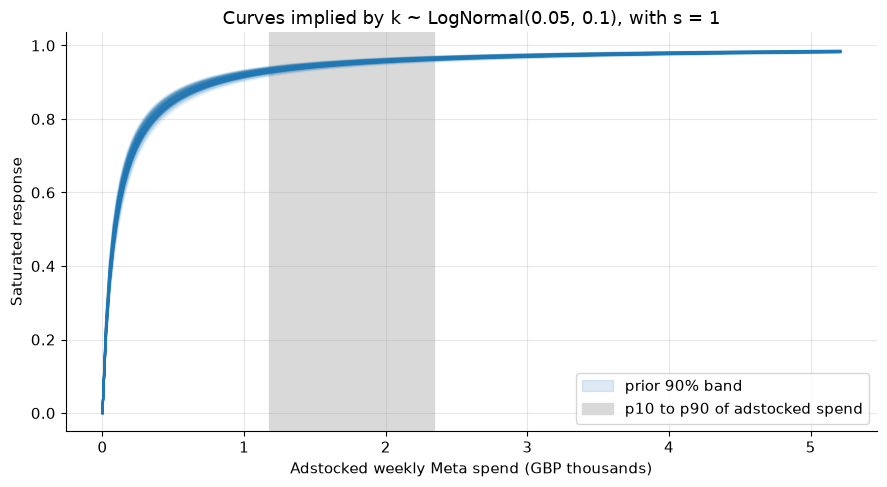

In [4]:
grid = np.linspace(0, adstocked.max() * 1.5, 200)
fig, ax = plt.subplots()
for k in k_draws[:100]:
    ax.plot(grid / 1e3, hill_saturation(grid, half=k * average, slope=1.0), color="C0", alpha=0.1)
band = np.percentile(
    [hill_saturation(grid, half=k * average, slope=1.0) for k in k_draws], [5, 95], axis=0
)
ax.fill_between(grid / 1e3, band[0], band[1], color="C0", alpha=0.15, label="prior 90% band")
ax.axvspan(
    levels[0] / 1e3, levels[2] / 1e3, color="0.85", zorder=0, label="p10 to p90 of adstocked spend"
)
ax.set_xlabel("Adstocked weekly Meta spend (GBP thousands)")
ax.set_ylabel("Saturated response")
ax.set_title(f"Curves implied by k ~ LogNormal({k_median}, {k_sigma}), with s = 1")
ax.legend()
fig.tight_layout()

## Self-check

The last check reveals what this synthetic world knows and a real one would not: the curve the Sedge generator actually used for Meta ($k$ = `HALF_MULT['meta']`, $s$ = 1).
A prior meeting the brief should contain it.

In [5]:
true_response = hill_saturation(
    levels, half=HALF_MULT[channel] * average, slope=HILL_SLOPE[channel]
)
print(f"true k: {HALF_MULT[channel]}; true response at p10, p50, p90: {np.round(true_response, 2)}")

checks = {
    "p50 median response in [0.3, 0.7]": 0.3 <= med[1] <= 0.7,
    "p50 90% range reaches below 0.3 and above 0.7": lo[1] < 0.3 and hi[1] > 0.7,
    "under 5% of curves above 0.9 at p10": np.mean(response[:, 0] > 0.9) < 0.05,
    "under 5% of curves below 0.05 at p90": np.mean(response[:, 2] < 0.05) < 0.05,
    "true curve inside the prior's 90% range at all three levels": bool(
        np.all((true_response >= lo) & (true_response <= hi))
    ),
}
for name, ok in checks.items():
    print(f"{name}: {'PASS' if ok else 'FAIL'}")
print("Self-check: PASS" if all(checks.values()) else "Self-check: FAIL")

true k: 1.071; true response at p10, p50, p90: [0.39 0.47 0.56]
p50 median response in [0.3, 0.7]: FAIL
p50 90% range reaches below 0.3 and above 0.7: FAIL
under 5% of curves above 0.9 at p10: FAIL
under 5% of curves below 0.05 at p90: PASS
true curve inside the prior's 90% range at all three levels: FAIL
Self-check: FAIL
